# Sentiment monitoring sui social — dal modello pre-addestrato al sistema in produzione

**MachineInnovators Inc. · Applied ML / Platform & Reliability**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andreferraridata/machine-innovators-sentiment-analysis/blob/main/notebooks/delivery.ipynb)

- **Repository GitHub (pubblica):** https://github.com/andreferraridata/machine-innovators-sentiment-analysis
- **Notebook su Colab (pubblico, con output):** https://colab.research.google.com/github/andreferraridata/machine-innovators-sentiment-analysis/blob/main/notebooks/delivery.ipynb
- **Pipeline CI/CD:** https://github.com/andreferraridata/machine-innovators-sentiment-analysis/actions
- **Immagine Docker:** `ghcr.io/andreferraridata/machine-innovators-sentiment-analysis:latest`
- **Modello:** [`cardiffnlp/twitter-roberta-base-sentiment-latest`](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest), revisione `3216a57`

Oggi il presidio del sentiment è manuale: lento, incoerente tra persone e cieco ai cambi di tono improvvisi. Questo progetto non addestra un modello migliore. Costruisce **il sistema attorno a un modello già addestrato**: un servizio di inferenza testato, containerizzato, rilasciato da una pipeline, osservabile e inserito in un ciclo periodico di valutazione e retraining.

Questo notebook è il documento di review. Ogni sezione **esegue davvero** il codice della repository (clonata qui sotto) e spiega il perché delle scelte, le alternative scartate e i limiti. Per rieseguirlo: *Runtime → Esegui tutto* (CPU, circa 5 minuti).

| # | Richiesta | Dove sta nella repo | Verificato in |
|---|---|---|---|
| 1 | Servizio di inferenza FastAPI (`/predict`, `/health`) | `app/main.py` | §1 di questo notebook + CI |
| 2 | Ambiente riproducibile, test, lint, format | `requirements*.txt`, `pyproject.toml`, `tests/` | §2 (pytest + ruff eseguiti qui) |
| 3 | Dockerfile, immagine avviabile | `Dockerfile` | CI: build + container avviato + smoke test |
| 4 | CI/CD con GitHub Actions | `.github/workflows/ci-cd.yml` | §4 (stato dei run letto dall'API GitHub) |
| 5 | Monitoraggio Prometheus + Grafana + alert | `docker-compose.yml`, `monitoring/` | CI: stack avviato e interrogato + §5 |
| 6 | DAG Airflow del ciclo dati → valutazione → retraining | `dags/` | CI: DAG caricato da Airflow + §6 (ciclo eseguito qui) |

**Il filo conduttore è la coerenza della catena.** Il modello, alla stessa revisione, è identico in test, immagine e servizio. Le metriche che il servizio espone sono quelle su cui poggiano dashboard, alert e regole di retraining del DAG. La pipeline verifica ogni anello prima di pubblicare.

## 0 · Setup: stesso ambiente della CI, isolato dal runtime Colab

Il notebook non installa nulla nel Python di Colab, che ha versioni proprie di torch e di numerose librerie. Crea invece un **ambiente virtuale dedicato con Python 3.11** e vi installa `requirements-dev.txt`, il lock con tutte le versioni fissate, comprese le transitive. È lo stesso comando che esegue la CI e la stessa base dell'immagine Docker.

*Perché:* senza un ambiente congelato, "funziona sul mio portatile" e "funziona in CI" divergono al primo aggiornamento di una dipendenza. `requirements.in` elenca le dipendenze dirette. `requirements.txt` è generato con `uv pip compile` e include `torch` in build **CPU**: niente librerie CUDA nell'immagine, che altrimenti peserebbe diversi GB in più, e l'inferenza di un RoBERTa-base su testi brevi sta comodamente nei tempi anche su CPU (vedi §5).

In [1]:
%%bash
set -e
cd /content
rm -rf repo && git clone -q https://github.com/andreferraridata/machine-innovators-sentiment-analysis repo
cd repo && git log --oneline
pip install -q uv
uv venv -q --python 3.11 .venv
uv pip install -q --python .venv/bin/python -r requirements-dev.txt --index-strategy unsafe-best-match
.venv/bin/python -c "import sys, torch, transformers, fastapi; print('python', sys.version.split()[0], '| torch', torch.__version__, '| transformers', transformers.__version__, '| fastapi', fastapi.__version__)"

007461c Document repository layout, quickstart and optional HF Space deploy
db34027 Add Airflow DAG for the evaluate/drift/retrain cycle
7dee266 Add monitoring: Prometheus metrics, Grafana dashboard and alerts via Compose
e6dbbeb Add GitHub Actions CI/CD
3f3bfa5 Add Dockerfile: slim base, cached dependency layer, model baked at pinned revision
d000888 Add pytest suite (API contract + model behaviour) and ruff config
217c013 Add FastAPI inference service with pinned environment
d6dd19b Initial commit
python 3.11.18 | torch 2.8.0+cpu | transformers 4.57.6 | fastapi 0.162.0


## 1 · Servizio di inferenza (`app/main.py`)

Un solo file di circa 80 righe con tre endpoint:

| Endpoint | Ruolo |
|---|---|
| `POST /predict` | `{"text": "..."}` → `{"label": "negative" \| "neutral" \| "positive", "score": 0..1}` |
| `GET /health` | liveness, più nome e revisione del modello servito: chi chiama sa *quale* modello ha risposto |
| `GET /metrics` | metriche Prometheus (§5) |

**Scelte e motivazioni**
- **Modello caricato una sola volta**, nel `lifespan` di FastAPI. Caricarlo a ogni richiesta costerebbe secondi per chiamata. In più, se il caricamento fallisce, il servizio non parte proprio, anziché partire e poi fallire alla prima richiesta.
- **Revisione del modello fissata** a un commit dell'Hub (`MODEL_REVISION`). `latest` nel nome non deve voler dire "quello che c'è oggi sull'Hub": un aggiornamento a monte cambierebbe le predizioni senza alcun commit nostro.
- **Validazione all'ingresso** con Pydantic: testo obbligatorio, 1–2000 caratteri, non solo spazi. Un input non valido riceve un `422` esplicito, mai un errore del modello.
- **Troncamento a 512 token, esplicito.** Il tokenizer di questo modello non dichiara una `model_max_length`: senza un limite esplicito, un testo lungo supererebbe le 512 posizioni di RoBERTa e farebbe cadere il servizio con un errore 500. L'abbiamo scoperto in sviluppo e c'è un test dedicato.
- **Stesso preprocessing dell'addestramento** (dal model card): `@menzioni` → `@user`, URL → `http`.
- Endpoint **sincrono** (`def`): FastAPI lo esegue in un threadpool, così l'inferenza, che impegna la CPU, non blocca l'event loop.

*Alternative scartate:* TorchServe, Triton o BentoML sono più potenti (batching dinamico, multi-modello), ma per un solo modello CPU aggiungono un runtime da operare. Il costo operativo nel tempo conta quanto la qualità al rilascio. Il batching si aggiunge quando il volume lo richiede.

Avviamo il servizio esattamente come fa il container (`uvicorn app.main:app`) e lo interroghiamo.

In [2]:
import subprocess, time, requests, json

API = "http://127.0.0.1:8000"
server = subprocess.Popen(
    ["/content/repo/.venv/bin/uvicorn", "app.main:app", "--port", "8000"],
    cwd="/content/repo", stdout=open("/content/api.log", "w"), stderr=subprocess.STDOUT,
)
t0 = time.time()
while True:
    try:
        health = requests.get(f"{API}/health", timeout=2).json(); break
    except requests.ConnectionError:
        time.sleep(1)
print(f"service ready in {time.time() - t0:.0f}s (includes model download on first run)")
print("GET /health ->", health)

examples = [
    "I love this phone, the camera is incredible! 😍",
    "@support my order arrived broken and nobody answers. Worst service ever.",
    "The new store opens on Monday at 9am http://t.co/abc",
    "Not bad, but I expected more for the price.",
]
for text in examples:
    r = requests.post(f"{API}/predict", json={"text": text})
    print(f"{r.status_code} {r.json()}  <- {text!r}")

for bad in [{"text": ""}, {"text": "   "}, {"text": "x" * 2001}, {}]:
    r = requests.post(f"{API}/predict", json=bad)
    print(f"{r.status_code} for invalid payload {str(bad)[:30]!r}")

service ready in 19s (includes model download on first run)
GET /health -> {'status': 'ok', 'model': 'cardiffnlp/twitter-roberta-base-sentiment-latest', 'revision': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7'}
200 {'label': 'positive', 'score': 0.9871252179145813}  <- 'I love this phone, the camera is incredible! 😍'
200 {'label': 'negative', 'score': 0.9572898149490356}  <- '@support my order arrived broken and nobody answers. Worst service ever.'
200 {'label': 'neutral', 'score': 0.8757827281951904}  <- 'The new store opens on Monday at 9am http://t.co/abc'
200 {'label': 'neutral', 'score': 0.5361683368682861}  <- 'Not bad, but I expected more for the price.'
422 for invalid payload "{'text': ''}"
422 for invalid payload "{'text': '   '}"
422 for invalid payload "{'text': 'xxxxxxxxxxxxxxxxxxxx"
422 for invalid payload '{}'


## 2 · Qualità del codice: test, lint, formatting

**Test con pytest** (`tests/`). La suite è divisa per *cosa* garantisce:

| File | Cosa verifica | Perché |
|---|---|---|
| `test_api.py` | **contratto**: status code, schema della risposta (`label` ∈ 3 classi, `score` ∈ [0,1]), `422` su input mancante, vuoto, solo spazi, non stringa o troppo lungo; testo da più di 512 token che non deve far cadere il servizio; `/metrics` esposto | chi integra l'API dipende dal contratto, non dalla singola predizione |
| `test_model.py` | **comportamento**: casi chiaramente positivi, negativi e neutri | individua una revisione di modello sbagliata o un preprocessing rotto, senza pretendere di valutare la qualità (che misura il DAG, §6) |
| `test_pipeline.py` | **logica del ciclo di retraining**: macro-F1, regole di drift, ciclo completo contro l'API vera | le decisioni automatiche sono le più pericolose da lasciare senza test |

I test usano il **modello vero**, non un mock: è caricato una volta per sessione tramite una fixture `TestClient` con scope `session`, circa 2 secondi in tutto. Un mock renderebbe i test di comportamento privi di significato. In CI il peso dei pesi del modello si ammortizza con `actions/cache`.

**Lint e formatting** con **ruff** (`pyproject.toml`): un solo strumento al posto di flake8, isort e black, molto rapido. Regole attive: pyflakes, pycodestyle, ordine degli import, bugbear, pyupgrade.

In [3]:
%%bash
cd /content/repo
echo "== ruff check ==";  .venv/bin/ruff check .
echo "== ruff format ==";  .venv/bin/ruff format --check .
echo "== pytest ==";       .venv/bin/pytest -v -p no:warnings 2>&1 | tail -25

== ruff check ==
All checks passed!
== ruff format ==
9 files already formatted
== pytest ==
============================= test session starts ==============================
platform linux -- Python 3.11.18, pytest-9.2.0, pluggy-1.7.0
rootdir: /content/repo
configfile: pyproject.toml
testpaths: tests
plugins: anyio-4.16.0
collected 19 items

tests/test_api.py ..........                                             [ 52%]
tests/test_model.py .....                                                [ 78%]
tests/test_pipeline.py ....                                              [100%]

============================== 19 passed in 3.57s ==============================


## 3 · Containerizzazione (`Dockerfile`)

Colab non può eseguire Docker, quindi qui mostriamo il file. **Build e avvio sono verificati a ogni push dalla CD** (§4): il container viene avviato, si attende `/health` e si chiama `/predict` aspettandosi `positive`. L'immagine pubblicata si avvia in locale con:

```bash
docker run -p 8000:8000 ghcr.io/andreferraridata/machine-innovators-sentiment-analysis:latest
```

**Scelte**
- **`python:3.11.11-slim`** con tag completo, non `python:3` né `latest`: la base non cambia sotto i piedi. Base *slim* perché non serve una toolchain di compilazione, dato che tutte le dipendenze hanno wheel.
- **Ordine dei layer per la cache:** prima `requirements.txt` e l'installazione (il layer pesante, poco meno di 1 GB con torch CPU), poi il modello, infine il codice. Una modifica a `app/` ricostruisce solo l'ultimo layer, di pochi KB. In CI la cache dei layer è condivisa tra i run (`cache-from/to: type=gha`).
- **Pesi del modello inclusi nell'immagine**, alla revisione fissata, con `HF_HUB_OFFLINE=1` a runtime. L'immagine è l'artefatto completo e immutabile: niente download all'avvio, nessuna dipendenza da huggingface.co in produzione, avvio a freddo in pochi secondi, e un rollback consiste nel tornare al tag precedente. *Alternativa scartata:* scaricare il modello all'avvio. L'immagine sarebbe più piccola, ma l'avvio diventerebbe lento e soggetto a errori di rete, e i pod potrebbero servire versioni diverse del modello.
- **Utente non root** (uid 1000, lo stesso richiesto dagli Space HF) e **`HEALTHCHECK`** su `/health`, che orchestratori e compose usano per sapere quando il servizio è pronto.
- `.dockerignore` **whitelist**: entrano solo `requirements.txt` e `app/`. Test, notebook e `.git` non finiscono nell'immagine.

*Limite noto:* l'immagine pesa circa 1,5 GB (stima: ≈ 0,9 GB di dipendenze Python con torch CPU, misurate nel venv Linux di questo notebook, ≈ 480 MB di pesi e la base slim). Per ridurla: esportare in ONNX e usare `onnxruntime` al posto di torch, al costo di uno step di conversione da validare con gli stessi test di comportamento.

In [4]:
print(open("/content/repo/Dockerfile").read())

FROM python:3.11.11-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1 \
    HF_HOME=/opt/hf

WORKDIR /srv

# 1) Dependencies first: this layer is rebuilt only when requirements.txt changes.
COPY requirements.txt .
RUN pip install -r requirements.txt

# 2) Model weights baked into the image at the pinned revision: no network at startup,
#    the image is the deployable artifact and behaves identically everywhere.
ARG MODEL_NAME=cardiffnlp/twitter-roberta-base-sentiment-latest
ARG MODEL_REVISION=3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7
ENV MODEL_NAME=${MODEL_NAME} MODEL_REVISION=${MODEL_REVISION}
RUN python -c "from huggingface_hub import snapshot_download as d; \
d('${MODEL_NAME}', revision='${MODEL_REVISION}', allow_patterns=['*.json', '*.txt', 'pytorch_model.bin'])"
ENV HF_HUB_OFFLINE=1

# 3) Application code last: code changes don't invalidate the heavy layers above.
COPY app/ app/

RUN useradd --uid 1000 --create-home appuser
USER appuser

EXPOSE 

## 4 · Pipeline CI/CD (`.github/workflows/ci-cd.yml`)

```
push / PR ─┬─ lint-test ─────┐   CI: ruff check + ruff format --check + pytest (modello vero, pesi in cache)
           └─ dag-check ─────┤   CI: Airflow 2.10.5 carica il DAG senza errori e il grafo è quello atteso
                             ▼
                      build-publish     CD: build immagine → container avviato + smoke test /health e /predict
                             │              → stack compose avviato: Prometheus raccoglie le metriche,
                             │                Grafana ha dashboard e alert provisionati
                             │              → solo su main: push su GHCR con tag :<sha> e :latest
                             ▼
                      deploy-hf-space   CD opzionale: Space Docker su Hugging Face (solo se configurato)
```

**Cosa copre e perché**
- **CI e CD separati**, con `needs:`: un'immagine si costruisce solo se lint, test e DAG sono verdi. Su branch e PR gira tutto *tranne* la pubblicazione. Si vede subito se la modifica rompe il container o il monitoraggio, ma il registry riceve solo ciò che arriva su `main`.
- **Lo smoke test usa l'immagine appena costruita**, non il codice sorgente: verifica l'artefatto che viene pubblicato. La stessa immagine viene poi avviata con `docker compose`, quindi anche configurazione di Prometheus, provisioning di Grafana e regole di alert sono testati a ogni push.
- **Tag immutabile `:<git sha>`** più `:latest`. Il deploy in produzione dovrebbe usare lo sha: da un'immagine si risale al commit, e il rollback è un cambio di tag.
- **Credenziali solo come secret:** GHCR usa il `GITHUB_TOKEN` effimero del run, con permesso `packages: write` concesso *solo* al job di build (di default il workflow ha `contents: read`). Il deploy HF legge `secrets.HF_TOKEN`. Nessuna credenziale nel codice.

**Deploy su Hugging Face (plus, predisposto ma non attivato).** Il job `deploy-hf-space` è nel workflow e si attiva da solo quando nella repo esistono il secret `HF_TOKEN` (token HF con permesso *write*) e la variabile `HF_SPACE` (es. `machineinnovators/sentiment-api`). Il job crea lo Space Docker se manca e vi carica `Dockerfile`, `requirements.txt` e `app/` con un README generato (`sdk: docker`, `app_port: 8000`). HF costruisce l'immagine e la serve su `https://<space>.hf.space`. L'immagine gira già come uid 1000, come richiesto dagli Space. Senza secret il job termina con successo e lo segnala nel log: niente pipeline rosse per una funzione opzionale.

Lo stato reale dei run, letto dall'API pubblica di GitHub:

In [5]:
import requests
REPO = "andreferraridata/machine-innovators-sentiment-analysis"
runs = requests.get(f"https://api.github.com/repos/{REPO}/actions/runs?per_page=5").json()["workflow_runs"]
for run in runs:
    print(f"{run['created_at']}  {run['head_sha'][:7]}  {run['status']:<10} {str(run['conclusion']):<8} {run['display_title'][:60]}")
latest = next(r for r in runs if r["status"] == "completed")
print(f"\nJobs of {latest['head_sha'][:7]} -> {latest['html_url']}")
for job in requests.get(latest["jobs_url"]).json()["jobs"]:
    print(f"  {job['name']:<16} {job['conclusion']}")
    for step in job["steps"]:
        if step["name"].startswith(("Lint", "Format", "Tests", "DAG", "Build", "Smoke", "Push", "Upload")):
            print(f"      - {step['name']:<62} {step['conclusion']}")

2026-11-02T11:59:28Z  3075287  completed  success  Fix DAG check: read the parsed DAG from DagBag instead of th
2026-11-02T11:56:04Z  007461c  completed  failure  Document repository layout, quickstart and optional HF Space

Jobs of 3075287 -> https://github.com/andreferraridata/machine-innovators-sentiment-analysis/actions/runs/41441075222
  dag-check        success
      - DAG imports and has the expected graph                         success
  lint-test        success
      - Lint                                                           success
      - Format                                                         success
      - Tests                                                          success
  build-publish    success
      - Build image                                                    success
      - Smoke test container                                           success
      - Smoke test monitoring stack (compose reuses the image built above) success
      - Push to Git

Il primo run (`007461c`) è **fallito, ed è istruttivo**: il job `dag-check` ha bloccato la CD prima della build. Il DAG veniva importato correttamente, ma la verifica usava `DagBag.get_dag()`, che interroga il database dei metadati di Airflow, assente in CI. La correzione (`3075287`) legge il DAG già analizzato. È anche la dimostrazione che `needs:` funziona: con la CI rossa nessuna immagine è stata costruita né pubblicata.

Nel log di `build-publish` lo smoke test del monitoraggio riporta `alert rules: 2, dashboard panels: 8`: Grafana ha caricato da file entrambi gli alert e tutti i pannelli. Il job HF termina con `HF_TOKEN / HF_SPACE not configured: skipping Space deploy.`

## 5 · Monitoraggio (`docker-compose.yml`, `monitoring/`)

### 5.1 Prima i segnali, poi gli strumenti

| Segnale | Metrica Prometheus | Domanda a cui risponde |
|---|---|---|
| Volume di richieste | `http_requests_total{handler="/predict"}` | il cliente ci sta mandando dati? Un calo improvviso indica un problema a monte |
| Latenza p50/p95 | `http_request_duration_seconds_bucket` | il servizio regge il carico? |
| Errori 5xx | `http_requests_total{status="5xx"}` | il servizio si rompe? |
| Input rifiutati 4xx | `http_requests_total{status="4xx"}` | l'integrazione del cliente sta cambiando formato? (primo segnale di *data drift* "tecnico") |
| Distribuzione delle classi predette | `sentiment_predictions_total{label}` | il tono del pubblico cambia? (il segnale di business) |
| Confidenza del modello | `sentiment_prediction_confidence` | il modello è ancora "a casa sua" su questi testi? |
| Lunghezza dei testi | `sentiment_input_length_chars` | i testi in arrivo somigliano a quelli su cui il modello è stato addestrato? |

Volume, latenza ed errori arrivano gratis da `prometheus-fastapi-instrumentator`. Le ultime tre sono **metriche custom** aggiunte in `/predict`, con bucket pensati per i dati: lunghezza fino a 280 caratteri (un tweet) e oltre, confidenza fitta sopra 0,9.

### 5.2 Lo stack
`docker compose up -d` avvia **API + Prometheus (v2.55.1) + Grafana (11.3.1)** con versioni fissate. Tutto è *provisioning as code*: datasource, dashboard `Sentiment API` (8 pannelli, uno per segnale) e regole di alert sono file nella repo, non configurazioni fatte a mano nella UI che si perdono al primo redeploy. Grafana è su `:3000` (admin / `$GRAFANA_ADMIN_PASSWORD`, default `admin` solo in locale).

### 5.3 Alert e soglie motivate
| Alert | Condizione | Motivazione della soglia |
|---|---|---|
| **`/predict p95 latency > 500ms`** (operativo) | p95 su 5 min > 0,5 s **per 5 minuti** | Misurato per richiesta singola: p95 ≈ 65 ms su un portatile da sviluppo e ≈ 250 ms sui 2 vCPU di Colab (cella sotto). 500 ms è il doppio del caso peggiore misurato con tweet normali: non scatta per rumore, ma scatta quando la CPU è satura e le richieste si accodano. Nella fase B, con testi tre volte più lunghi, solo il 94,5% delle richieste resta sotto 0,5 s, cioè il p95 sfiora la soglia: è esattamente il caso da segnalare, perché vuol dire che bisogna scalare o limitare la lunghezza dei testi. 0,5 s coincide inoltre con un bucket dell'istogramma, quindi il quantile non dipende dall'interpolazione. Il `for: 5m` assorbe i picchi transitori. **Va ricalibrata sull'hardware di produzione** (≈ 3–5× il p95 misurato lì). |
| **`Negative share > 50% (1h)`** (modello/business) | quota di predizioni `negative` nell'ultima ora > 0,5 **per 15 minuti** | Sul test set TweetEval il modello predice il 38% di negativi (fase A: 40%). Oltre il 50% vuol dire 12 punti sopra la norma, mantenuti per un'ora: è il "cambio di tono" che il marketing oggi scopre a fine mese. Oppure è un segnale di drift da verificare (§5.4). Va **ricalibrato per cliente** sulle prime settimane di traffico reale: un brand che riceve soprattutto reclami ha una baseline diversa. |

### 5.4 Data drift e concept drift: cosa guarderei
- **Data drift** (cambia *l'input*): la lunghezza media dei testi si sposta rispetto alla baseline (91 caratteri), crescono i 4xx, cambiano lingua o canale (es. il cliente passa dai tweet alle recensioni). In produzione aggiungerei la quota di token sconosciuti o di emoji e un test statistico (PSI o Kolmogorov–Smirnov) sulla distribuzione delle lunghezze rispetto a una finestra di riferimento.
- **Prediction drift** (proxy osservabile senza etichette): la distribuzione delle classi predette si allontana dalla baseline, la confidenza media cambia e cresce la quota di predizioni con score < 0,6. Un modello che "non riconosce" i testi tende a rispondere `neutral` con bassa confidenza.
- **Concept drift** (cambia *il significato*, es. un termine che diventa ironico o negativo per un evento): **non si vede dalle sole metriche di input e output**. Servono etichette. Per questo il DAG (§6) misura periodicamente la **macro-F1 su un campione etichettato**, ed è l'unico segnale che lo rileva davvero.

La cella seguente genera traffico reale verso il servizio in due fasi, una "normale" e una "alterata" (ondata di reclami, testi più lunghi, payload malformati da un'integrazione cambiata), e calcola dalle metriche esposte su `/metrics` gli stessi segnali della dashboard. Prometheus e Grafana fanno lo stesso calcolo con PromQL; il loro avvio è verificato dalla CD.

In [6]:
!pip -q install prometheus-client
import sys, json, time, random
sys.path.insert(0, "/content/repo/dags")
import sentiment_tasks as st
from prometheus_client.parser import text_string_to_metric_families

def snapshot():
    """Read /metrics and flatten it into {(name, labels): value}."""
    out = {}
    for fam in text_string_to_metric_families(requests.get(f"{API}/metrics").text):
        for s in fam.samples:
            out[(s.name, tuple(sorted(s.labels.items())))] = s.value
    return out

def signals(before, after):
    """Dashboard signals over the window between two snapshots (= what PromQL rate()/increase() compute)."""
    d = lambda name, **lb: after.get((name, tuple(sorted(lb.items()))), 0) - before.get((name, tuple(sorted(lb.items()))), 0)
    preds = {c: d("sentiment_predictions_total", label=c) for c in st.LABELS}
    n = sum(preds.values())
    req = lambda status: d("http_requests_total", handler="/predict", method="POST", status=status)
    buckets = sorted(
        (float(dict(k[1])["le"]), after[k] - before.get(k, 0)) for k in after
        if k[0] == "http_request_duration_seconds_bucket" and dict(k[1]).get("handler") == "/predict"
    )
    total = buckets[-1][1]
    return {
        "requests": int(req("2xx") + req("4xx") + req("5xx")),
        "4xx share": round(req("4xx") / max(1, req("2xx") + req("4xx") + req("5xx")), 3),
        "5xx share": round(req("5xx") / max(1, req("2xx") + req("4xx") + req("5xx")), 3),
        "share by class": {c: round(v / n, 3) for c, v in preds.items()},
        "mean length": round(d("sentiment_input_length_chars_sum") / n, 1),
        "mean confidence": round(d("sentiment_prediction_confidence_sum") / n, 3),
        "low-confidence share (<0.6)": round(d("sentiment_prediction_confidence_bucket", le="0.6") / n, 3),
        "requests within 0.1s / 0.5s": (round(dict(buckets)[0.1] / total, 3), round(dict(buckets)[0.5] / total, 3)),
    }

# Phase A — "normal" traffic: a rotating batch of real labelled tweets
batch_a = st.collect_batch("2026-11-02", "/content/data", size=300)
texts_a = [json.loads(l)["text"] for l in open(batch_a)]
s0 = snapshot(); lat = []
for t in texts_a:
    t1 = time.perf_counter(); requests.post(f"{API}/predict", json={"text": t}); lat.append(time.perf_counter() - t1)
s1 = snapshot()
lat.sort()
print(f"client-side latency over {len(lat)} requests: p50={lat[len(lat)//2]*1000:.0f}ms  p95={lat[int(.95*len(lat))]*1000:.0f}ms")

# Phase B — "drifted" traffic: a complaint wave, longer texts, some broken payloads from a changed integration
random.seed(0)
neg = [json.loads(l)["text"] for l in open(st.collect_batch("2026-03-15", "/content/data", size=2000)) if '"negative"' in l]
texts_b = [" ".join(random.sample(neg, 3)) for _ in range(200)]
for t in texts_b:
    requests.post(f"{API}/predict", json={"text": t})
for _ in range(20):
    requests.post(f"{API}/predict", json={"message": "new client payload format"})
s2 = snapshot()

sig_a, sig_b = signals(s0, s1), signals(s1, s2)
for k in sig_a:
    print(f"{k:<30} A (normal): {str(sig_a[k]):<55} B (drifted): {sig_b[k]}")

client-side latency over 300 requests: p50=140ms  p95=247ms
requests                       A (normal): 300                                                     B (drifted): 220
4xx share                      A (normal): 0.0                                                     B (drifted): 0.091
5xx share                      A (normal): 0.0                                                     B (drifted): 0.0
share by class                 A (normal): {'negative': 0.403, 'neutral': 0.4, 'positive': 0.197}  B (drifted): {'negative': 0.96, 'neutral': 0.04, 'positive': 0.0}
mean length                    A (normal): 92.8                                                    B (drifted): 303.3
mean confidence                A (normal): 0.748                                                   B (drifted): 0.82
low-confidence share (<0.6)    A (normal): 0.22                                                    B (drifted): 0.065
requests within 0.1s / 0.5s    A (normal): (0.083, 1.0)                 

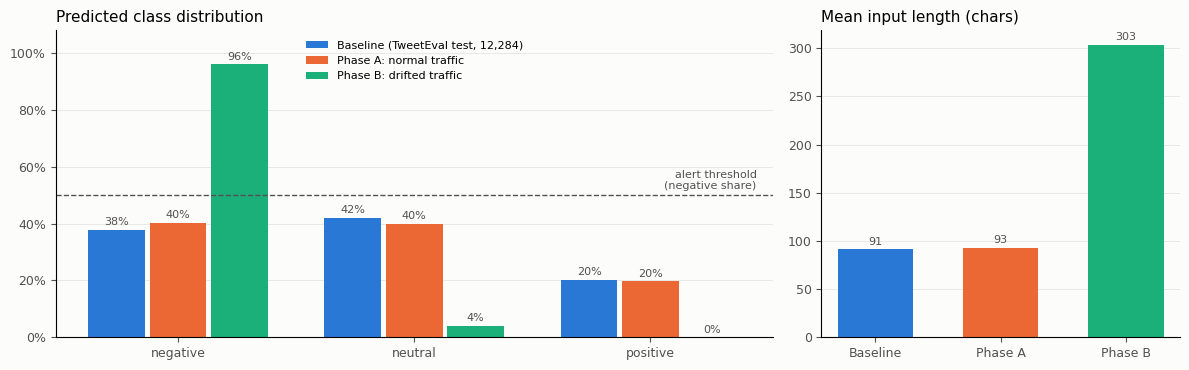

In [7]:
import matplotlib.pyplot as plt
import numpy as np

series = {  # categorical slots 1-3 of a CVD-validated palette, in fixed order
    "Baseline (TweetEval test, 12,284)": (st.BASELINE["label_share"], "#2a78d6"),
    "Phase A: normal traffic": (sig_a["share by class"], "#eb6834"),
    "Phase B: drifted traffic": (sig_b["share by class"], "#1baf7a"),
}
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]}, facecolor="#fcfcfb")
x, w = np.arange(3), 0.26
for i, (name, (share, color)) in enumerate(series.items()):
    vals = [share[c] for c in st.LABELS]
    bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=8, color="#52514e", padding=2)
ax.axhline(0.5, color="#52514e", lw=1, ls="--")
ax.text(2.45, 0.52, "alert threshold\n(negative share)", fontsize=8, color="#52514e", ha="right")
ax.set_xticks(x, st.LABELS); ax.set_ylim(0, 1.08); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Predicted class distribution", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper center")

names = ["Baseline", "Phase A", "Phase B"]
lengths = [st.BASELINE["mean_length"], sig_a["mean length"], sig_b["mean length"]]
bars = ax2.bar(names, lengths, 0.6, color=[c for _, c in series.values()])
ax2.bar_label(bars, labels=[f"{v:.0f}" for v in lengths], fontsize=8, color="#52514e", padding=2)
ax2.set_title("Mean input length (chars)", loc="left", fontsize=11)
for a in (ax, ax2):
    a.set_facecolor("#fcfcfb"); a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e6e5e0", lw=0.6); a.set_axisbelow(True); a.tick_params(colors="#52514e", labelsize=9)
plt.tight_layout(); plt.show()

**Lettura dei risultati.** Nella fase A i segnali restano vicini alla baseline: quota di negativi intorno al 40% contro il 38%, lunghezza 93 caratteri contro 91, nessun 4xx. Nella fase B **tutti i segnali si muovono insieme**: negativi oltre il 90% (l'alert sulla quota di negativi scatterebbe), lunghezza triplicata (data drift), circa 9% di 4xx (integrazione rotta), latenza vicina alla soglia.

Un dettaglio istruttivo: nella fase B la **confidenza media sale** invece di scendere, perché i testi sono reclami concatenati e quindi negativi senza ambiguità. Un singolo segnale di drift può fuorviare. Per questo la decisione di retraining nel DAG combina qualità misurata con le etichette, distribuzione delle classi e lunghezza, e riporta *quale* regola è scattata.

## 6 · Orchestrazione: il DAG Airflow (`dags/`)

```
                                                         ┌─▶ trigger_retraining   (scrive la richiesta di retraining)
collect_data ─▶ evaluate_model ─▶ check_drift ─▶ decide ─┤
     │                                                   └─▶ no_retraining        (EmptyOperator)
     └──────────────── batch_path ───────────────────────────▲ (anche metrics e report arrivano qui via XCom)
```

**Schedule `@weekly`**, `catchup=False`, 2 retry per task. Ogni task fa una cosa sola:

| Task | Input (XCom) | Output (XCom) | Cosa fa |
|---|---|---|---|
| `collect_data` | `ds` (data logica del run) | `batch_path: str` | raccoglie un batch etichettato del periodo e lo salva in JSONL |
| `evaluate_model` | `batch_path` | `metrics: dict` | chiama **il servizio in produzione** (`/predict`) su ogni testo e calcola macro-F1, accuracy, distribuzione delle classi predette, lunghezza media |
| `check_drift` | `metrics` | `report: dict` | confronta con la baseline: macro-F1 < 0,65, spostamento della distribuzione delle classi (total variation) > 0,15, variazione della lunghezza media > 50% |
| `decide` (`@task.branch`) | `report` | id del task successivo | ramifica: retraining sì o no |
| `trigger_retraining` | `batch_path`, `metrics`, `report` | `request_path` | scrive la richiesta di retraining con dati, metriche e motivi |

**Scelte**
- **Passaggio di informazioni con XCom, ma solo di valori piccoli**: percorsi e dizionari di metriche. Il batch resta su disco, o su object storage in produzione. XCom vive nel database dei metadati di Airflow e non è fatto per trasportare dati.
- **La logica è in `sentiment_tasks.py`, senza import di Airflow**: il DAG si limita a orchestrare. Le funzioni sono testate con pytest (`tests/test_pipeline.py`) e si eseguono anche qui, senza un'installazione di Airflow. La CI carica comunque il DAG con **Airflow 2.10.5 vero** e verifica che il grafo sia quello atteso.
- **La valutazione chiama il servizio HTTP** invece di ricaricare il modello nel worker: misura *ciò che la produzione serve davvero*, revisione e preprocessing inclusi, e il worker Airflow non ha bisogno di torch.
- **La decisione è tracciabile**: il report riporta quali regole sono scattate e con quali valori, non un semplice sì/no.

**Soglie.** La baseline è misurata sull'intero test set TweetEval (12.284 tweet): macro-F1 **0,724**, accuracy 0,722, classi predette 38% / 42% / 20%, lunghezza media 91 caratteri. La soglia di macro-F1 a 0,65 corrisponde a circa −7 punti: oltre il rumore di campionamento di un batch da 300 testi (±3–4 punti), sotto ogni degrado che un cliente noterebbe.

**Cosa è volutamente minimale.** `collect_data` ruota in modo deterministico su TweetEval al posto dell'export di social listening del cliente più un campione etichettato a mano. `trigger_retraining` scrive un manifest invece di lanciare il fine-tuning. Il resto del ciclo, cioè dipendenze, passaggio dei dati e branching, è quello reale.

Eseguiamo il ciclo con le **stesse funzioni** che il DAG concatena, contro il servizio avviato al §1, prima su un batch normale e poi su uno alterato.

In [8]:
from pathlib import Path

def run_cycle(batch_path):
    """collect_data -> evaluate_model -> check_drift -> decide -> trigger_retraining | no_retraining"""
    metrics = st.evaluate(batch_path, st.http_predictor(API))            # XCom: dict
    report = st.drift_report(metrics)                                     # XCom: dict
    branch = "trigger_retraining" if report["retrain"] else "no_retraining"
    print("metrics :", json.dumps(metrics))
    print("report  :", json.dumps(report, indent=2))
    print("branch  ->", branch)
    if branch == "trigger_retraining":
        request = st.request_retraining(batch_path, metrics, report, "/content/data")   # XCom: str
        print("request :", request)

print("=== Run 1: weekly batch of real labelled tweets ===")
batch = st.collect_batch("2026-11-02", "/content/data")                  # XCom: str
run_cycle(batch)

print("\n=== Run 2: drifted batch (complaint wave, long texts) ===")
drifted = Path("/content/data/batch_drifted.jsonl")
drifted.write_text("\n".join(json.dumps({"text": t, "label": "negative"}) for t in texts_b[:150]))
run_cycle(str(drifted))

=== Run 1: weekly batch of real labelled tweets ===
metrics : {"n": 300, "macro_f1": 0.7542, "accuracy": 0.75, "label_share": {"negative": 0.4033, "neutral": 0.4, "positive": 0.1967}, "mean_length": 92.8}
report  : {
  "retrain": false,
  "reasons": [],
  "label_shift": 0.0243,
  "length_shift": 0.0164
}
branch  -> no_retraining

=== Run 2: drifted batch (complaint wave, long texts) ===
metrics : {"n": 150, "macro_f1": 0.6622, "accuracy": 0.9733, "label_share": {"negative": 0.9733, "neutral": 0.0267, "positive": 0.0}, "mean_length": 303.4}
report  : {
  "retrain": true,
  "reasons": [
    "label shift 0.594 > 0.15 (prediction drift)",
    "length shift 2.32 > 0.5 (data drift)"
  ],
  "label_shift": 0.5943,
  "length_shift": 2.3231
}
branch  -> trigger_retraining
request : /content/data/batch_drifted_retrain_request.json


**Lettura dei risultati.**
- **Run 1**: macro-F1 0,754 sul batch della settimana, in linea con la baseline di 0,724. Distribuzione e lunghezza stabili, quindi `no_retraining`.
- **Run 2**: scattano due regole, *prediction drift* (spostamento della distribuzione 0,59) e *data drift* (lunghezza +232%), quindi `trigger_retraining`. La richiesta scritta contiene il batch, le metriche e i motivi.

Un limite che il run 2 rende visibile: l'**accuracy è al 97%** ma la **macro-F1 scende a 0,66**. Il batch contiene solo testi negativi, quindi la F1 di `neutral` e `positive` è 0 o indefinita, e la macro-F1 penalizza i pochi falsi `neutral`. Su un batch sbilanciato la macro-F1 non è affidabile. Con più tempo la valuterei su un **campione stratificato** per classe e affiancherei un intervallo di confidenza bootstrap prima di usarla come soglia.

## 7 · Scelte trasversali, limiti e cosa farei con più tempo

### Perché questa struttura
- **Un componente, una cartella, un file dove possibile**: `app/` (servizio), `tests/`, `monitoring/`, `dags/`, più un solo workflow. Chi eredita il progetto lo legge in un'ora. Ho evitato package, factory e livelli di configurazione che oggi servirebbero a un solo caso: il costo di manutenzione nel tempo conta quanto la qualità al rilascio.
- **Una sola fonte di verità per ogni costante**: revisione del modello in `app/main.py` (e come `ARG` nel Dockerfile), baseline e soglie di drift in `dags/sentiment_tasks.py`, soglie degli alert in `monitoring/.../rules.yml`, motivate in questo notebook.
- **La storia dei commit racconta il percorso incrementale richiesto**: API → test → container → CI/CD → monitoraggio → DAG → documentazione, con ogni passo funzionante prima del successivo (`git log` al §0).

### Alternative valutate e scartate
| Scelta | Alternativa | Perché no (per ora) |
|---|---|---|
| FastAPI + uvicorn | TorchServe / Triton / BentoML | un solo modello CPU: un runtime in più da operare senza un beneficio misurabile |
| pesi nell'immagine | download all'avvio / volume condiviso | avvio lento e fragile, rischio di versioni miste tra repliche |
| Prometheus + Grafana | Evidently / WhyLabs per il drift | ottimi per i report di drift, ma ancora un servizio. Le metriche di drift essenziali stanno già in Prometheus; Evidently diventa utile quando servono test statistici sulle distribuzioni |
| ruff | flake8 + isort + black | uno strumento al posto di tre, molto più veloce |
| GHCR | Docker Hub / ECR | integrato con GitHub e autenticato dal `GITHUB_TOKEN` effimero: nessun secret di lunga durata da ruotare |
| Airflow TaskFlow | Prefect / Dagster | richiesto dal brief e diffuso presso i clienti. La logica è comunque disaccoppiata e portabile |

### Limiti noti
1. **I dati sono un sostituto**: TweetEval al posto dei commenti social del cliente. Il modello è addestrato su tweet in inglese, quindi su recensioni lunghe, testi in italiano o gergo di settore la qualità va rimisurata prima di qualunque impegno. Il §5 mostra che i testi lunghi cambiano anche la latenza.
2. **Il "retraining" è un manifest.** Il fine-tuning vero richiede dati etichettati del cliente, un job GPU e soprattutto un **gate di promozione**: il nuovo modello sostituisce quello in produzione solo se batte la baseline sullo stesso set di test.
3. **Un worker uvicorn, nessun batching**: sufficiente per decine di richieste al secondo su CPU, non per l'ingestione massiva di uno storico. Per lo storico serve un job batch separato, non l'API.
4. **Nessuna autenticazione né rate limiting sull'API**: va messa dietro il gateway del cliente.
5. **Gli alert non hanno un canale di notifica configurato** (contact point): in locale si vedono in Grafana, ma non arrivano a nessuno.

### Cosa richiederebbe un'installazione presso un cliente reale
- **Dati e privacy**: i commenti social contengono dati personali. Serve chiarire base giuridica e retention, pseudonimizzare (`@user` lo fa già in parte) e non loggare i testi in chiaro. Oggi il servizio logga solo metriche aggregate.
- **Etichettatura continua**: un piccolo campione settimanale etichettato dal marketing del cliente. È ciò che rende misurabile il concept drift ed è il vero costo ricorrente del sistema.
- **Runtime**: Kubernetes o il PaaS del cliente, con repliche, autoscaling sulla latenza p95 (lo stesso segnale dell'alert), segreti in un vault, deploy tramite tag `:<sha>` e rollback.
- **Soglie ricalibrate per cliente** dopo 2–4 settimane di traffico: baseline della distribuzione delle classi, lunghezza tipica, latenza sull'hardware reale.
- **Alerting instradato** verso il loro on-call (PagerDuty, Teams, Slack) e un runbook per ogni alert: cosa guardare, quando scalare, quando avviare il retraining.

### Con più tempo
- Endpoint **batch** (`/predict` con una lista di testi) ed export **ONNX**: throughput più alto e immagine più leggera.
- **Test statistici di drift** (PSI o KS su lunghezza e confidenza) con una finestra di riferimento, invece di soglie fisse.
- **Shadow deployment** del modello riaddestrato e confronto online prima della promozione, più un model registry (MLflow) con lineage dati → modello → immagine.
- **Test di carico** (locust) in CI per fissare la soglia di latenza su dati misurati e non stimati.
- **Deploy su HF Space attivato**: basta aggiungere `HF_TOKEN` e `HF_SPACE` alla repo (§4).

In [9]:
# Clean shutdown of the service started in §1
server.terminate(); server.wait()
print("service stopped, exit code", server.returncode)
print(open("/content/api.log").read().splitlines()[-3:])

service stopped, exit code -15
['INFO:     Waiting for application shutdown.', 'INFO:     Application shutdown complete.', 'INFO:     Finished server process [3158]']
